# 11 · Compare all runs

Every YOLO run in `runs/` that has a `weights/best.pt`:
1. **Training results** from Ultralytics (`results.csv`, `args`): what each run was trained on, how, for how long, and its best logged validation scores.
   These are scored on **each run's own** validation set, so they show how each run trained but **don't compare runs**.
2. **Training curves** on shared axes.
3. **One common evaluation:** every `best.pt` scored by Ultralytics `val()` on the **same** validation and test images, per class (box and mask P, R, F1, mAP50, mAP50-95). **This is the comparison.**
4. **Leakage check:** how many evaluation photos each run saw in training (matched by original photo name, so augmented copies count). A run that trained on test photos scores too well; read its numbers with that in mind.

Results go to `results/compare_runs/`.

In [1]:
import csv
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from dotenv import load_dotenv
from ultralytics import YOLO

from eval_utils import ensure_dataset

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")
OUT = ROOT / "results" / "compare_runs"
OUT.mkdir(parents=True, exist_ok=True)

C:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

- `RUNS`: found automatically (every `runs/*/weights/best.pt`). Edit the list to leave runs out.
- `EVAL_DATA`: the datasets for the common evaluation, as (Roboflow project, version, splits). The first is the `.env` dataset (validation + test). Add the fixed test set once it exists, e.g. `("lds_test", 1, ("test",))`. Each is downloaded on first use.

In [2]:
RUNS = sorted(p.parent.parent for p in (ROOT / "runs").glob("*/weights/best.pt"))
EVAL_DATA = [
    (os.environ["ROBOFLOW_PROJECT"], int(os.environ["ROBOFLOW_VERSION"]), ("val", "test")),
    # ("lds_test", 1, ("test",)),
]
BATCH = 8

EVAL = []  # (label, data.yaml, split)
for project, version, splits in EVAL_DATA:
    _, data_yaml = ensure_dataset(ROOT, project, version, os.environ["ROBOFLOW_API_KEY"], os.environ["ROBOFLOW_WORKSPACE"])
    EVAL += [(f"{project}-v{version} {split}", data_yaml, split) for split in splits]
print("runs:", *[r.name for r in RUNS], sep="\n  ")
print("evaluated on:", *[e[0] for e in EVAL], sep="\n  ")

# Chart style (colour-blind-checked categorical slots, one per run, fixed order)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
RUN_COLOR = {r.name: SERIES[i % len(SERIES)] for i, r in enumerate(RUNS)}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "legend.frameon": False, "lines.linewidth": 2, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def show_table(title, header, rows):
    rows = [[f"{v:.3f}" if isinstance(v, float) else str(v) for v in r] for r in rows]
    widths = [max(len(x) for x in col) for col in zip(header, *rows)]
    print(f"\n{title}")
    print("  ".join(h.ljust(w) for h, w in zip(header, widths)))
    print("  ".join("-" * w for w in widths))
    for r in rows:
        print("  ".join(x.ljust(w) for x, w in zip(r, widths)))


def read_results(run):
    with open(run / "results.csv") as f:
        rows = list(csv.DictReader(f))
    return [{k.strip(): float(v) for k, v in r.items() if v.strip()} for r in rows]

runs:
  labelassist-yolo26x-seg-v1_data-powdery-mildew-mbjv6-v2
  yolo26x-seg_data-v1
  yolo26x-seg_data-v2
evaluated on:
  lds_v1-v2 val
  lds_v1-v2 test


## 1. Training results (Ultralytics)

From each run's `results.csv` and the settings stored in its checkpoint:
- **Best epoch** is the epoch with the highest logged mask mAP50-95; `best.pt` is from Ultralytics' fitness, which usually picks the same epoch.
- **Train time** is the total wall-clock time.
- **Logged val scores** are on **that run's own** validation split; see section 3 for the fair comparison.

In [3]:
train_rows, curves = [], {}
for run in RUNS:
    res = read_results(run)
    curves[run.name] = res
    args = torch.load(run / "weights" / "best.pt", map_location="cpu", weights_only=False).get("train_args", {})
    best = max(res, key=lambda r: r.get("metrics/mAP50-95(M)", 0))
    last = res[-1]
    data = Path(str(args.get("data", ""))).parent.name or "?"
    train_rows.append({
        "run": run.name, "trained on": data, "start": Path(str(args.get("model", "?"))).name,
        "imgsz": args.get("imgsz"), "batch": args.get("batch"), "lr0": args.get("lr0"),
        "overlap_mask": args.get("overlap_mask"), "copy_paste": args.get("copy_paste"), "erasing": args.get("erasing"),
        "epochs planned": args.get("epochs"), "epochs trained": len(res), "best epoch": int(best["epoch"]),
        "train hours": round(last.get("time", 0) / 3600, 1),
        "val mask mAP50": best.get("metrics/mAP50(M)"), "val mask mAP50-95": best.get("metrics/mAP50-95(M)"),
        "val box mAP50": best.get("metrics/mAP50(B)"), "val box mAP50-95": best.get("metrics/mAP50-95(B)"),
        "val mask P": best.get("metrics/precision(M)"), "val mask R": best.get("metrics/recall(M)"),
        "final train seg_loss": last.get("train/seg_loss"), "final val seg_loss": last.get("val/seg_loss"),
    })

keys = list(train_rows[0])
for chunk in (keys[:12], keys[:1] + keys[12:]):
    show_table("Training results", chunk, [[r[k] for k in chunk] for r in train_rows])
with open(OUT / "training_results.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(train_rows)


Training results
run                                                      trained on                      start           imgsz  batch  lr0    overlap_mask  copy_paste  erasing  epochs planned  epochs trained  best epoch
-------------------------------------------------------  ------------------------------  --------------  -----  -----  -----  ------------  ----------  -------  --------------  --------------  ----------
labelassist-yolo26x-seg-v1_data-powdery-mildew-mbjv6-v2  powdery-mildew-mbjv6-v2-yolo26  best.pt         1024   8      0.001  False         0.300       0.400    200             115             55        
yolo26x-seg_data-v1                                      leaf-dis-seg-v1-yolo            yolo26x-seg.pt  1024   8      0.001  True          0.000       0.400    150             50              39        
yolo26x-seg_data-v2                                      lds_v1-v2-yolo                  yolo26x-seg.pt  1024   8      0.001  True          0.000       0.400    150  

## 2. Training curves

Per epoch, every run on the same axes. Validation curves use each run's own validation set, so compare their **shape** (still improving? overfitting?) rather than their height.

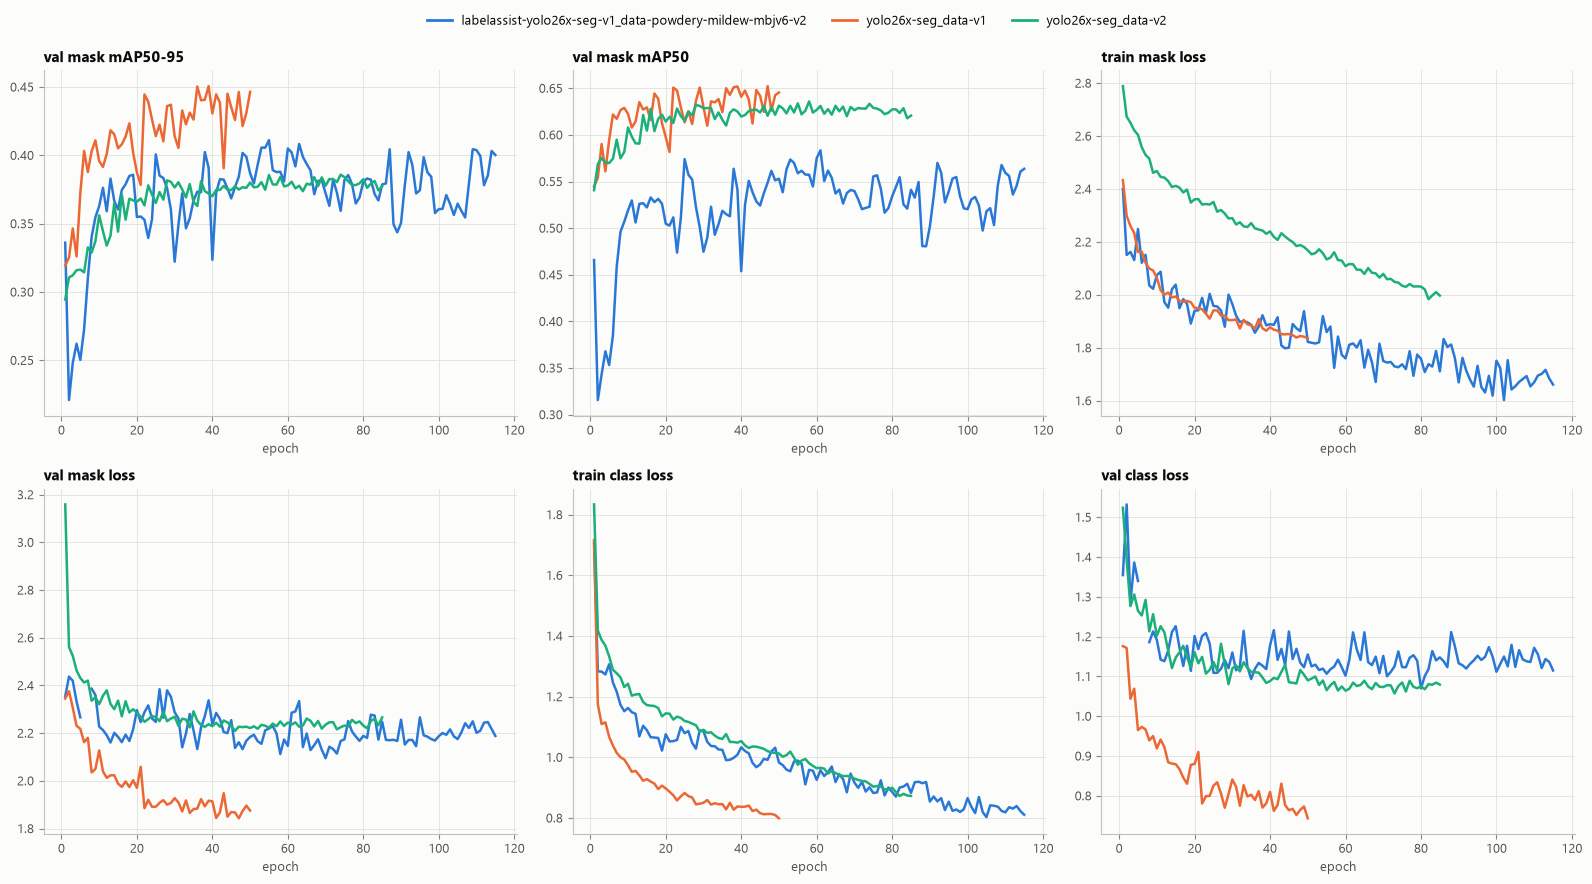

In [4]:
PANELS = [("metrics/mAP50-95(M)", "val mask mAP50-95"), ("metrics/mAP50(M)", "val mask mAP50"),
          ("train/seg_loss", "train mask loss"), ("val/seg_loss", "val mask loss"),
          ("train/cls_loss", "train class loss"), ("val/cls_loss", "val class loss")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (key, title) in zip(axes.ravel(), PANELS):
    ends = []
    for name, res in curves.items():
        xs = [r["epoch"] for r in res if key in r]
        ys = [r[key] for r in res if key in r]
        if xs:
            ax.plot(xs, ys, color=RUN_COLOR[name], linewidth=1.8)
            ends.append((xs[-1], ys[-1], name))
    ax.set(title=title, xlabel="epoch")
legend = [plt.Line2D([], [], color=RUN_COLOR[r.name], linewidth=2, label=r.name) for r in RUNS]
fig.legend(handles=legend, loc="upper center", ncols=min(len(RUNS), 3), bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
fig.savefig(OUT / "training_curves.png")
plt.show()

## 3. Common evaluation: every best.pt on the same images

Ultralytics `val()` at each run's training image size. P, R and F1 are at the confidence that maximises mean F1. A run whose class names don't match the dataset is skipped.

In [5]:
def f1(p, r):
    return float(2 * p * r / (p + r)) if p + r else 0.0


eval_rows = []
for run in RUNS:
    model = YOLO(run / "weights" / "best.pt")
    imgsz = model.ckpt["train_args"]["imgsz"]
    for label, data_yaml, split in EVAL:
        data_names = yaml.safe_load(open(data_yaml))["names"]
        data_names = data_names if isinstance(data_names, list) else [data_names[k] for k in sorted(data_names)]
        if sorted(model.names.values()) != sorted(data_names):
            print(f"{run.name}: classes {list(model.names.values())} ≠ {data_names}, skipped on {label}")
            continue
        m = model.val(data=str(data_yaml), split=split, imgsz=imgsz, batch=BATCH, workers=0, plots=False, verbose=False)
        counts = getattr(m, "nt_per_class", None)
        for j, c in enumerate(m.ap_class_index):
            bp, br, b50, b = (float(v) for v in m.box.class_result(j))
            sp, sr, s50, s = (float(v) for v in m.seg.class_result(j))
            eval_rows.append({"run": run.name, "eval": label, "class": model.names[int(c)],
                              "instances": int(counts[int(c)]) if counts is not None else "",
                              "box_P": bp, "box_R": br, "box_F1": f1(bp, br), "box_mAP50": b50, "box_mAP50-95": b,
                              "mask_P": sp, "mask_R": sr, "mask_F1": f1(sp, sr), "mask_mAP50": s50, "mask_mAP50-95": s})
        eval_rows.append({"run": run.name, "eval": label, "class": "all",
                          "instances": int(sum(counts)) if counts is not None else "",
                          "box_P": float(m.box.mp), "box_R": float(m.box.mr), "box_F1": f1(m.box.mp, m.box.mr),
                          "box_mAP50": float(m.box.map50), "box_mAP50-95": float(m.box.map),
                          "mask_P": float(m.seg.mp), "mask_R": float(m.seg.mr), "mask_F1": f1(m.seg.mp, m.seg.mr),
                          "mask_mAP50": float(m.seg.map50), "mask_mAP50-95": float(m.seg.map)})
    del model
    torch.cuda.empty_cache()

COLS = ["box_P", "box_R", "box_F1", "box_mAP50", "box_mAP50-95", "mask_P", "mask_R", "mask_F1", "mask_mAP50", "mask_mAP50-95"]
for label, _, _ in EVAL:
    for cls in ("all", "leaf", "leaf_spot", "powdery_mildew"):
        rows = [r for r in eval_rows if r["eval"] == label and r["class"] == cls]
        if rows:
            show_table(f"{label} · {cls}", ["run", "inst"] + COLS, [[r["run"], r["instances"]] + [r[c] for c in COLS] for r in rows])
with open(OUT / "common_evaluation.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(eval_rows[0])); w.writeheader(); w.writerows(eval_rows)

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)


YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 226.0±73.0 MB/s, size: 132.7 KB)


val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\labels.cache... 146 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 146/146 34.0Mit/s 0.0s

val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\images\IMG_1846_JPG_jpg.rf.fe64a5a31a2e9b6ff40dbe68bbccb499.jpg: 1 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\images\IMG_1872_JPG_jpg.rf.9674923cf927d2a896558fda5853b2d8.jpg: 1 duplicate labels removed
val: C:\Users\bp67339\PCPL\plant disease detection\training\datasets\lds_v1-v2-yolo\valid\images\IMG_1939_JPG_jpg.rf.f00535048e7209ed3fddb9d9636084bd.jpg: 3 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 1.6s/it 0.5s<28.2s

... (120 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.0it/s 3.4s

                   all         76       5330      0.756      0.627      0.679      0.441      0.715      0.562      0.594      0.343


Speed: 0.4ms preprocess, 19.3ms inference, 0.0ms loss, 1.6ms postprocess per image



lds_v1-v2 val · all
run                                                      inst  box_P  box_R  box_F1  box_mAP50  box_mAP50-95  mask_P  mask_R  mask_F1  mask_mAP50  mask_mAP50-95
-------------------------------------------------------  ----  -----  -----  ------  ---------  ------------  ------  ------  -------  ----------  -------------
labelassist-yolo26x-seg-v1_data-powdery-mildew-mbjv6-v2  9499  0.671  0.533  0.594   0.578      0.373         0.675   0.507   0.579    0.544       0.327        
yolo26x-seg_data-v1                                      9499  0.707  0.525  0.603   0.565      0.370         0.681   0.496   0.574    0.519       0.319        
yolo26x-seg_data-v2                                      9499  0.740  0.637  0.685   0.683      0.454         0.712   0.583   0.641    0.624       0.374        

lds_v1-v2 val · leaf
run                                                      inst  box_P  box_R  box_F1  box_mAP50  box_mAP50-95  mask_P  mask_R  mask_F1  mask_mAP50  mask_

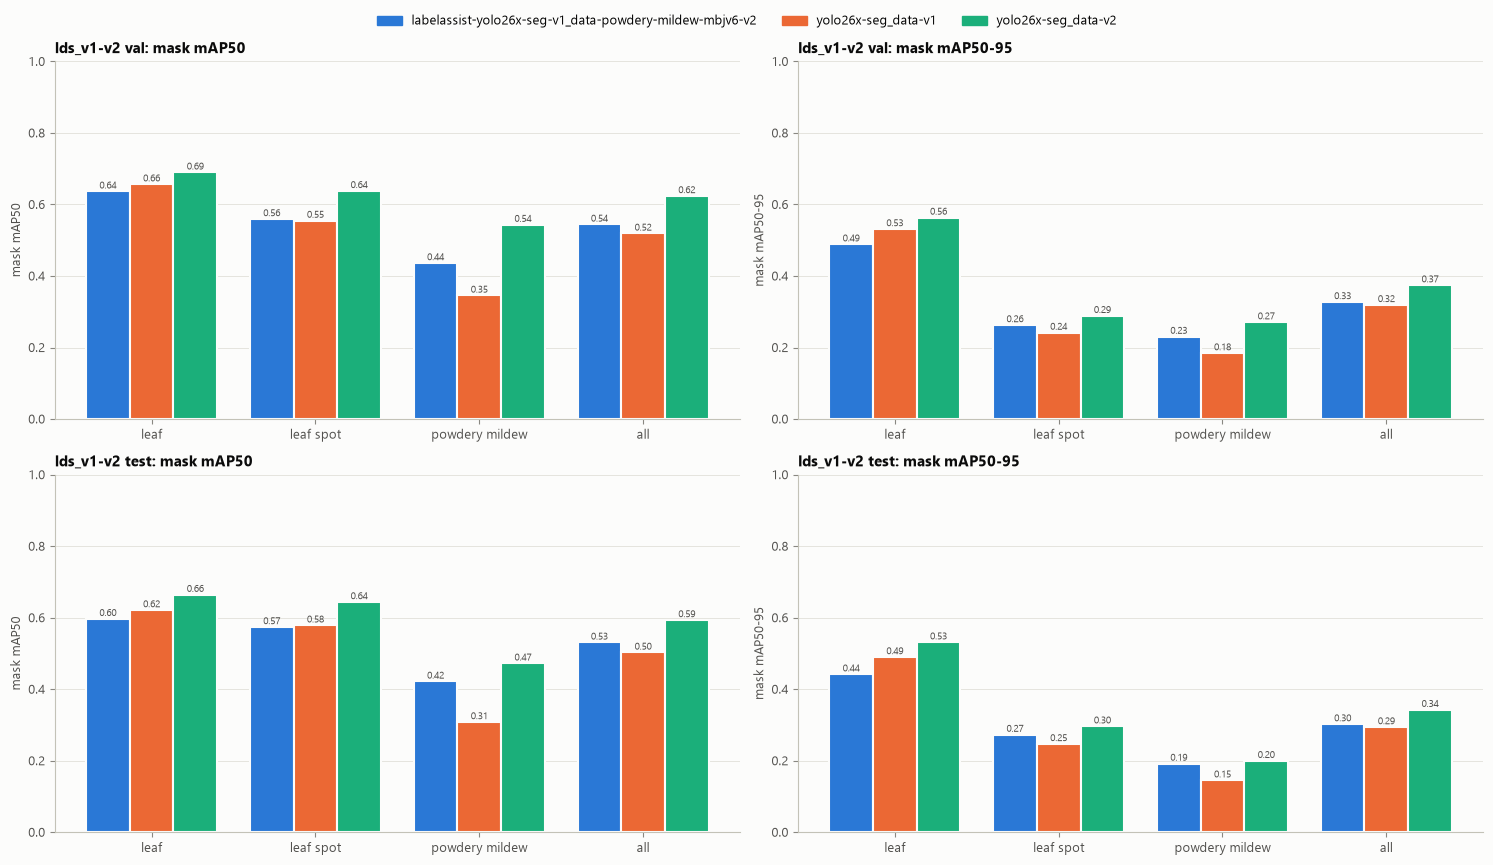

In [6]:
# Mask mAP50 and mAP50-95 per class: one panel per evaluation set and metric, one bar per run, values labelled
CLASSES_PLOT = ("leaf", "leaf_spot", "powdery_mildew", "all")
fig, axes = plt.subplots(len(EVAL), 2, figsize=(15, 4.2 * len(EVAL)), squeeze=False)
for axr, (label, _, _) in zip(axes, EVAL):
    for ax, metric in zip(axr, ("mask_mAP50", "mask_mAP50-95")):
        runs_here = [r.name for r in RUNS if any(e["run"] == r.name and e["eval"] == label for e in eval_rows)]
        w = 0.8 / max(len(runs_here), 1)
        x = np.arange(len(CLASSES_PLOT))
        for i, name in enumerate(runs_here):
            vals = [next((e[metric] for e in eval_rows if e["run"] == name and e["eval"] == label and e["class"] == c), np.nan)
                    for c in CLASSES_PLOT]
            bars = ax.bar(x + (i - (len(runs_here) - 1) / 2) * w, vals, w, color=RUN_COLOR[name], edgecolor=SURFACE,
                          linewidth=1.5, label=name, zorder=2)
            for b, v in zip(bars, vals):
                if np.isfinite(v):
                    ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 2), textcoords="offset points",
                                ha="center", fontsize=7, color=INK2)
        ax.set(xticks=x, xticklabels=[c.replace("_", " ") for c in CLASSES_PLOT], ylim=(0, 1), ylabel=metric.replace("_", " "))
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{label}: {metric.replace('_', ' ')}")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RUN_COLOR[r.name], label=r.name) for r in RUNS], loc="upper center",
           ncols=min(len(RUNS), 3), bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
fig.savefig(OUT / "common_evaluation.png")
plt.show()

## 4. Leakage check

For each run: how many photos of each evaluation set also appear in **that run's training split**, matched by the original photo name (Roboflow names copies `<photo>_jpg.rf.<hash>.jpg`, so augmented copies are caught too). Anything above 0 means that run has seen those test or validation photos, so its scores there are optimistic. Compare runs only where the overlap is 0.

In [7]:
def source(name):
    return name.split(".rf.")[0]


def split_dir(data_yaml, split):
    d = yaml.safe_load(open(data_yaml))
    base = Path(d.get("path", Path(data_yaml).parent))
    key = {"val": "val", "test": "test", "train": "train"}[split]
    rel = d.get(key)
    return (base / rel) if rel else None


eval_sources = {}
for label, data_yaml, split in EVAL:
    folder = split_dir(data_yaml, split)
    eval_sources[label] = {source(p.name) for p in folder.glob("*")} if folder and folder.exists() else set()

rows = []
for run in RUNS:
    args = torch.load(run / "weights" / "best.pt", map_location="cpu", weights_only=False).get("train_args", {})
    train_yaml = Path(str(args.get("data", "")))
    train_dir = split_dir(train_yaml, "train") if train_yaml.exists() else None
    seen = {source(p.name) for p in train_dir.glob("*")} if train_dir and train_dir.exists() else None
    for label, srcs in eval_sources.items():
        rows.append([run.name, label, len(srcs), "training data not found" if seen is None else len(srcs & seen)])
show_table("Evaluation photos also in each run's training split", ["run", "evaluation set", "photos", "seen in training"], rows)


Evaluation photos also in each run's training split
run                                                      evaluation set  photos  seen in training
-------------------------------------------------------  --------------  ------  ----------------
labelassist-yolo26x-seg-v1_data-powdery-mildew-mbjv6-v2  lds_v1-v2 val   146     0               
labelassist-yolo26x-seg-v1_data-powdery-mildew-mbjv6-v2  lds_v1-v2 test  76      0               
yolo26x-seg_data-v1                                      lds_v1-v2 val   146     71              
yolo26x-seg_data-v1                                      lds_v1-v2 test  76      31              
yolo26x-seg_data-v2                                      lds_v1-v2 val   146     0               
yolo26x-seg_data-v2                                      lds_v1-v2 test  76      0               


## Reading the comparison

- **Choose by section 3**, on rows where the leakage check shows 0.
- For the app, mask mAP is only part of the story. Coverage accuracy per disease (`08_test_report`, `09_tune_inference`) decides which model goes to the backend; run 08 with each candidate's `RUN`.
- Validation is for choosing; test is the final, reported number. If a model is chosen because of its test score, the test score is no longer an unbiased estimate.